# Diabetes Prediction - Notebook
Predict whether a patient has diabetes from basic medical measurements (Pima Indians Diabetes dataset).

Sections: 1. Data loading & cleaning · 2. EDA · 3. Feature importance · 4. Model training & tuning · 5. Final model

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, roc_curve
from sklearn.feature_selection import mutual_info_classif

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load and clean the data
Source: https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv .

In [2]:
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
columns = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "diabetes_pedigree", "age", "outcome"]
try:
    df = pd.read_csv("data/diabetes.csv", header=None, names=columns)
except FileNotFoundError:
    df = pd.read_csv(URL, header=None, names=columns)
print(df.shape)
df.head()

(768, 9)


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pregnancies        768 non-null    int64  
 1   glucose            768 non-null    int64  
 2   blood_pressure     768 non-null    int64  
 3   skin_thickness     768 non-null    int64  
 4   insulin            768 non-null    int64  
 5   bmi                768 non-null    float64
 6   diabetes_pedigree  768 non-null    float64
 7   age                768 non-null    int64  
 8   outcome            768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,count,mean,std,min,25%,50%,75%,max
pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
blood_pressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
skin_thickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
bmi,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
diabetes_pedigree,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


**Problem found:** glucose, blood pressure, skin thickness, insulin and BMI have minimum value 0, which is impossible for a living person. These zeros mean *not measured*, so we convert them to NaN.

In [4]:
zero_as_missing = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]
print((df[zero_as_missing] == 0).sum())
df[zero_as_missing] = df[zero_as_missing].replace(0, np.nan)
print("\nMissing values (%):")
print((df.isna().mean() * 100).round(1))
print("\nDuplicate rows:", df.duplicated().sum())

glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
dtype: int64

Missing values (%):
pregnancies           0.0
glucose               0.7
blood_pressure        4.6
skin_thickness       29.6
insulin              48.7
bmi                   1.4
diabetes_pedigree     0.0
age                   0.0
outcome               0.0
dtype: float64

Duplicate rows: 0


## 2. EDA

### Target distribution

outcome
0    500
1    268
Name: count, dtype: int64
outcome
0    0.651
1    0.349
Name: proportion, dtype: float64


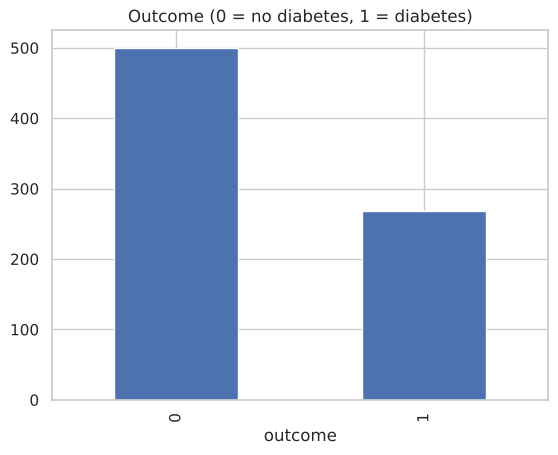

In [5]:
print(df.outcome.value_counts())
print(df.outcome.value_counts(normalize=True).round(3))
df.outcome.value_counts().plot(kind="bar", title="Outcome (0 = no diabetes, 1 = diabetes)")
plt.show()

The target is moderately imbalanced (about 65% / 35%), so we use **ROC AUC** as the main metric.

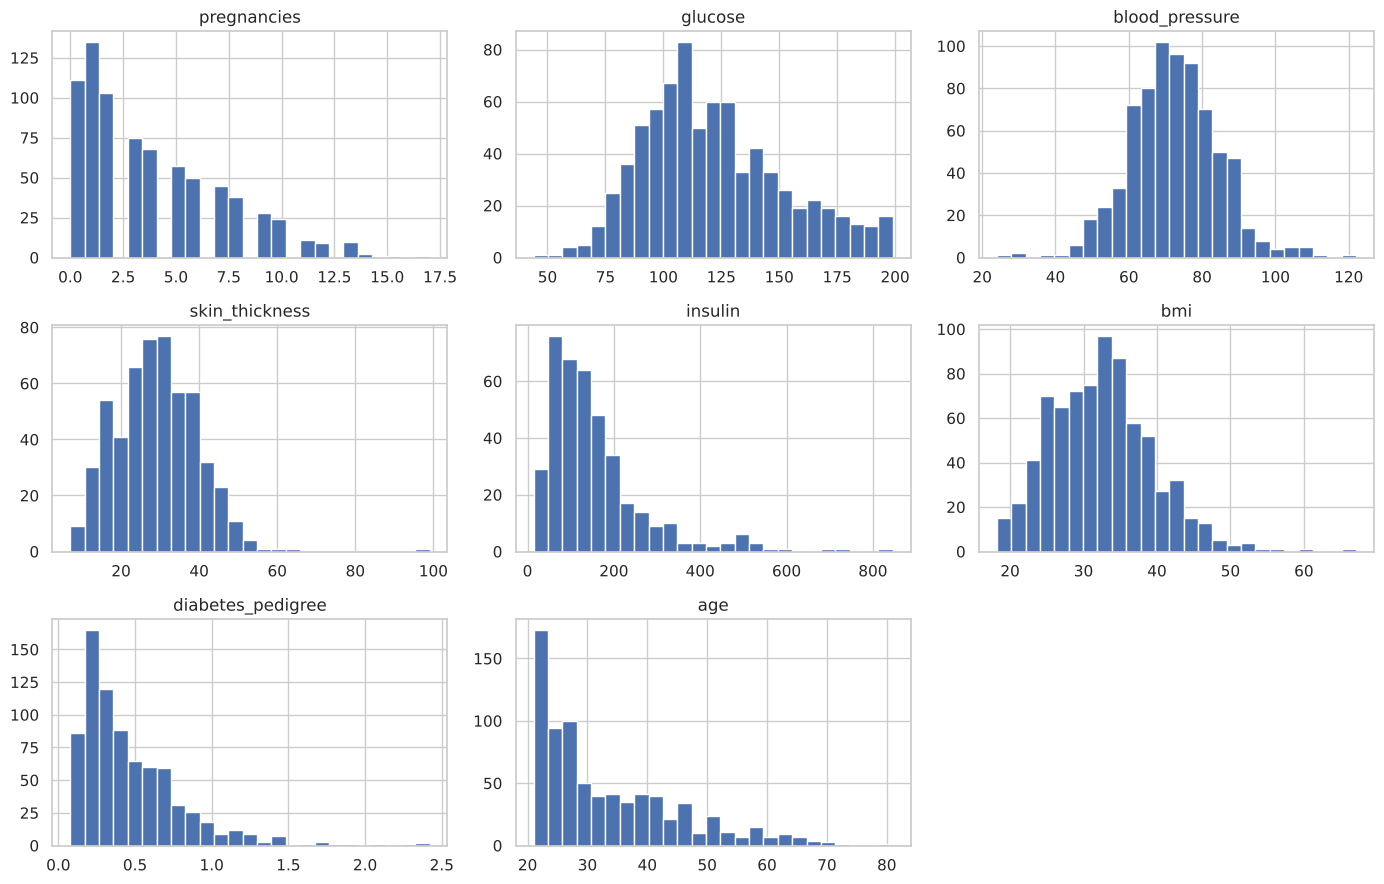

In [6]:
features = [c for c in df.columns if c != "outcome"]
df[features].hist(bins=25, figsize=(14, 9))
plt.tight_layout(); plt.show()

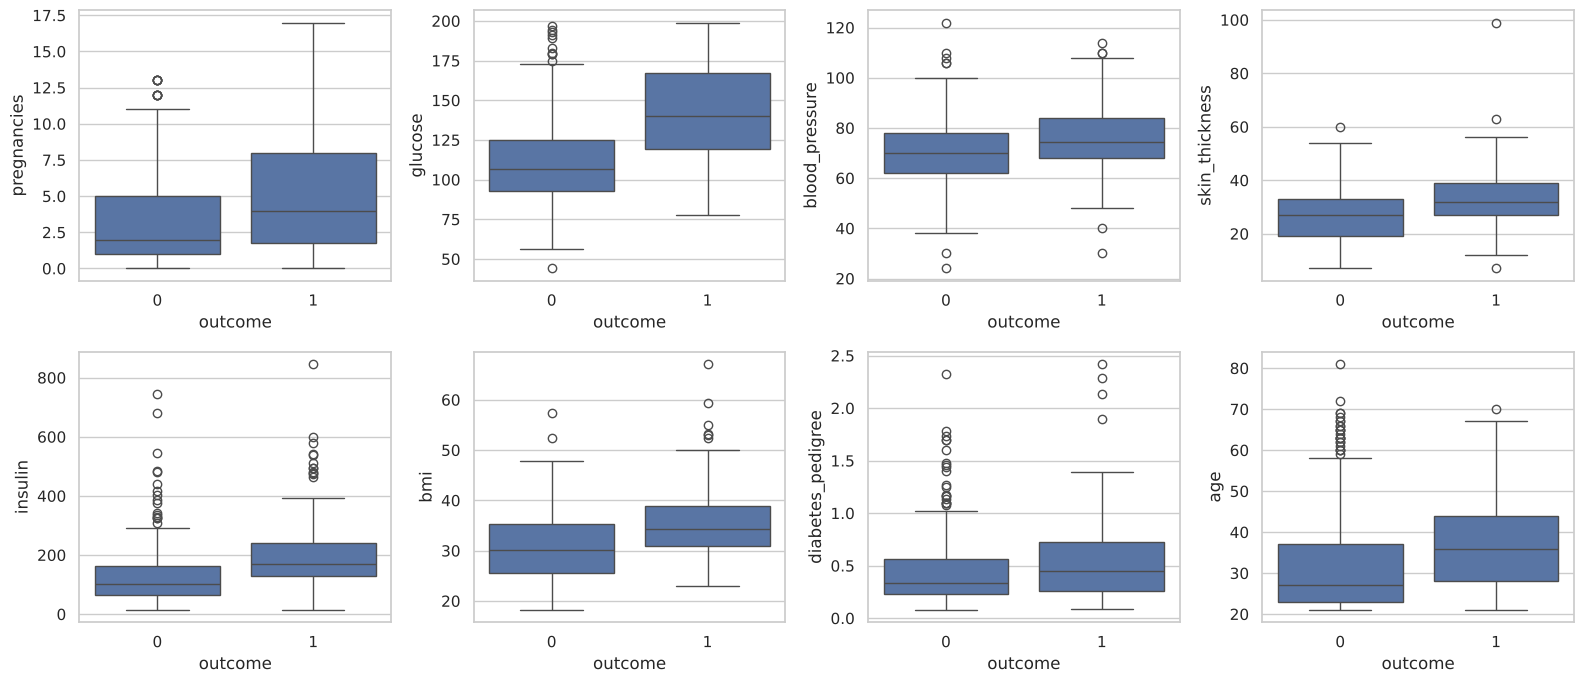

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=df, x="outcome", y=col, ax=ax)
plt.tight_layout(); plt.show()

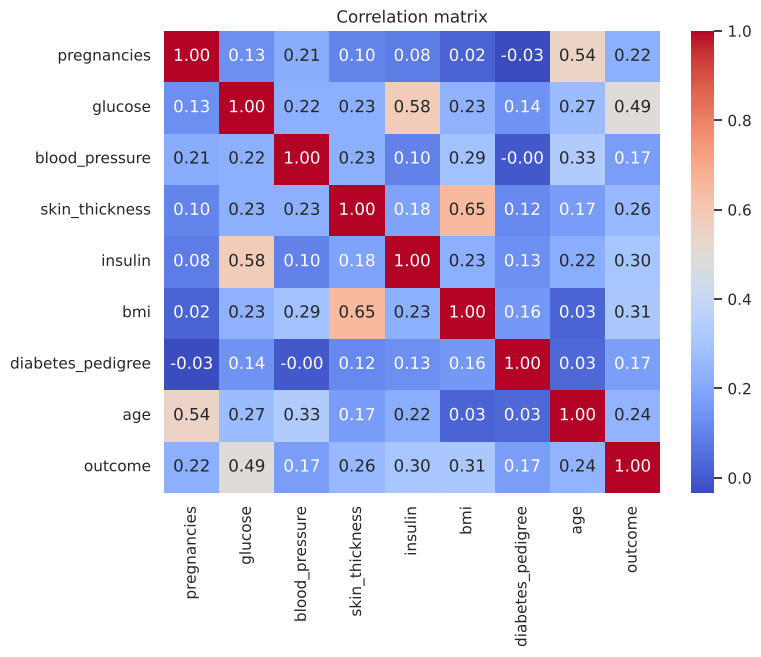

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix"); plt.show()

## 3. Feature importance

glucose              0.495
bmi                  0.314
insulin              0.303
skin_thickness       0.259
age                  0.238
pregnancies          0.222
diabetes_pedigree    0.174
blood_pressure       0.171
Name: outcome, dtype: float64


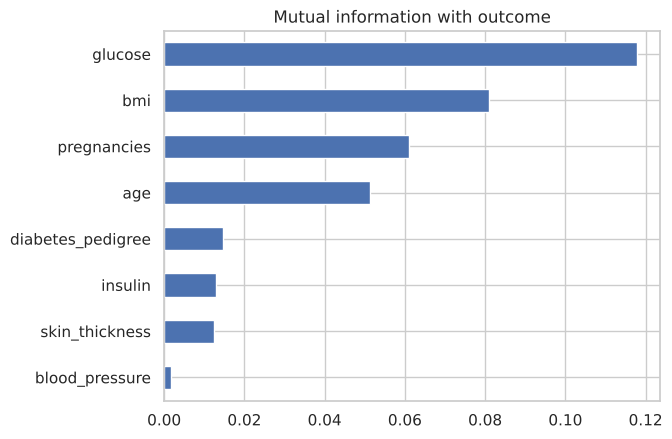

In [9]:
# Correlation with target
print(df.corr()["outcome"].drop("outcome").sort_values(ascending=False).round(3))

# Mutual information (after median imputation)
X_imp = df[features].fillna(df[features].median())
mi = pd.Series(mutual_info_classif(X_imp, df.outcome, random_state=RANDOM_STATE), index=features)
mi.sort_values().plot(kind="barh", title="Mutual information with outcome")
plt.show()

**Takeaway:** glucose is by far the strongest predictor, followed by BMI, age and pregnancies.

## 4. Model training and tuning
Split 80% train / 20% test (stratified). Cross-validation on the training part is used for tuning. Imputation and scaling are inside a `Pipeline`, so there is no data leakage.

In [10]:
X = df[features]; y = df["outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_pipeline(model):
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler()),
                     ("model", model)])

# Baseline: a shallow decision tree
base = make_pipeline(DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))
print("Baseline tree CV AUC:", cross_val_score(base, X_train, y_train, cv=cv, scoring="roc_auc").mean().round(3))

Baseline tree CV AUC: 0.759


In [11]:
candidates = {
    "logistic_regression": (make_pipeline(LogisticRegression(max_iter=1000)),
                            {"model__C": [0.01, 0.1, 1, 10]}),
    "random_forest": (make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE)),
                      {"model__n_estimators": [100, 300],
                       "model__max_depth": [3, 5, 8],
                       "model__min_samples_leaf": [1, 5, 10]}),
    "gradient_boosting": (make_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE)),
                          {"model__n_estimators": [50, 100, 200],
                           "model__learning_rate": [0.01, 0.05, 0.1],
                           "model__max_depth": [2, 3]}),
}
results, fitted = [], {}
for name, (pipe, grid) in candidates.items():
    search = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
    proba = search.predict_proba(X_test)[:, 1]
    fitted[name] = search
    results.append({"model": name,
                    "cv_auc": round(search.best_score_, 3),
                    "test_auc": round(roc_auc_score(y_test, proba), 3),
                    "test_accuracy": round(accuracy_score(y_test, proba >= 0.5), 3),
                    "best_params": search.best_params_})
results_df = pd.DataFrame(results).sort_values("cv_auc", ascending=False)
results_df

,model,cv_auc,test_auc,test_accuracy,best_params
0,logistic_regression,0.844,0.810,0.688,{'model__C': 0.1}
1,random_forest,0.841,0.811,0.734,"{'model__max_depth': 5, 'model__min_samples_le..."
2,gradient_boosting,0.830,0.815,0.721,"{'model__learning_rate': 0.05, 'model__max_dep..."


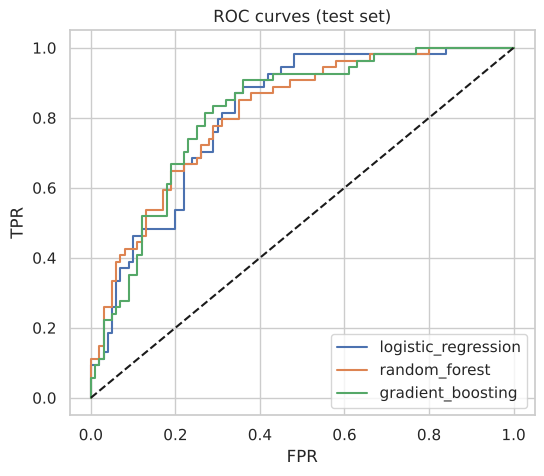

In [12]:
plt.figure(figsize=(6, 5))
for name, s in fitted.items():
    fpr, tpr, _ = roc_curve(y_test, s.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("FPR"); plt.ylabel("TPR")
plt.legend(); plt.title("ROC curves (test set)"); plt.show()

## 5. Final model
The model with the best cross-validated AUC is selected. `train.py` repeats exactly this process, refits the winner on all data and saves it to `model.bin`.

In [13]:
best_name = results_df.iloc[0]["model"]
print("Selected model:", best_name)
print(results_df.iloc[0]["best_params"])

Selected model: logistic_regression
{'model__C': 0.1}
